# Account Feature Distribution Explorer

This notebook visualizes the spread of the behavioral features in `src/features_with_labels.csv`. It includes overall distributions, missing values, label coverage, label-wise comparisons, and a two-dimensional PCA projection.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

data_path = Path("src/features_with_labels.csv")
if not data_path.exists():
    data_path = Path("../src/features_labeled.csv")

df = pd.read_csv(data_path)
df["label"] = df["label"].fillna("Unlabeled").replace("", "Unlabeled")
feature_columns = df.select_dtypes(include=np.number).columns.tolist()

print(f"Loaded {len(df):,} accounts and {len(feature_columns)} numeric features from {data_path}")
display(df.head())

Loaded 1,053 accounts and 33 numeric features from ..\src\features_labeled.csv


,author,average_mac_cdfa_t,variance_mac_cdfa_t,num_clusters_cdfa_t,average_mac_cdfa_c,variance_mac_cdfa_c,num_clusters_cdfa_c,average_mac_cdfa_r,variance_mac_cdfa_r,num_clusters_cdfa_r,...,daily_transfer,in_degree_of_transfer,out_degree_of_transfer,entropy_of_in_degree_accounts,entropy_of_out_degree_accounts,steem_created_account,average_transfer_per_blog_or_reply,average_transfer_per_blog,average_transfer_per_reply,label
0,moosa.amin,10.186205,0.004386,1,1.000000,0.000000,1,0.0,0.0,0,...,0.005844,6,0,1.747868,0.000000,0,0.075000,0.075000,0.0,B
1,zina1,5.058889,0.048668,1,1.580356,0.025203,1,0.0,0.0,0,...,0.007603,8,1,1.972247,0.000000,0,0.100000,0.100000,0.0,H
2,rubroa,5.978137,0.004733,2,2.000000,0.000000,2,0.0,0.0,0,...,0.002971,3,0,1.098612,0.000000,1,0.014228,0.014228,0.0,B
3,rootiness,1.000000,0.000000,1,2.036830,0.242628,1,0.0,0.0,0,...,0.367749,40,33,2.971672,2.978308,1,0.117647,0.125000,0.0,B
4,potterswheel,5.839547,0.026275,1,2.074139,0.081282,2,0.0,0.0,0,...,0.035425,13,2,2.376961,0.636514,0,0.427273,0.427273,0.0,B


## Dataset profile and missing values

The summary table reports the central tendency and quantiles for every numeric feature. The second chart highlights features with missing observations.

In [9]:
summary = df[feature_columns].describe().T[["count", "mean", "std", "min", "50%", "max"]]
display("Overall summary across all accounts")
display(summary.style.format("{:.3f}"))

labeled_df = df[df["label"] != "Unlabeled"].copy()
if labeled_df.empty:
    print("No labeled accounts available for per-label statistics.")
else:
    label_means = labeled_df.groupby("label")[feature_columns].mean().T
    display("Mean feature values by label")
    display(label_means.style.format("{:.3f}"))


'Overall summary across all accounts'

,count,mean,std,min,50%,max
average_mac_cdfa_t,1053.000,7.288,3.081,0.048,6.909,19.758
variance_mac_cdfa_t,1053.000,0.035,0.051,0.000,0.019,0.695
num_clusters_cdfa_t,1053.000,1.335,0.498,1.000,1.000,3.000
average_mac_cdfa_c,1053.000,16.735,8.209,0.990,15.657,53.716
variance_mac_cdfa_c,1053.000,0.723,1.869,0.000,0.229,30.621
num_clusters_cdfa_c,1053.000,1.334,0.486,1.000,1.000,3.000
average_mac_cdfa_r,1053.000,7.373,3.867,0.000,7.582,30.199
variance_mac_cdfa_r,1053.000,0.060,0.214,0.000,0.029,4.808
num_clusters_cdfa_r,1053.000,1.206,0.580,0.000,1.000,3.000
average_response_time,1053.000,544646.018,3310098.396,0.000,81531.000,72699837.762


'Mean feature values by label'

label,B,H
average_mac_cdfa_t,4.855,8.183
variance_mac_cdfa_t,0.053,0.029
num_clusters_cdfa_t,1.445,1.295
average_mac_cdfa_c,13.483,17.931
variance_mac_cdfa_c,0.500,0.805
num_clusters_cdfa_c,1.435,1.297
average_mac_cdfa_r,5.954,7.894
variance_mac_cdfa_r,0.066,0.058
num_clusters_cdfa_r,1.205,1.206
average_response_time,649577.343,506080.350


## Distribution of feature values

Feature scales differ substantially, so these panels use `log1p` values. This keeps long-tailed activity and transfer measures visible while preserving the ordering of non-negative values. The boxplots provide a compact view of spread and outliers.

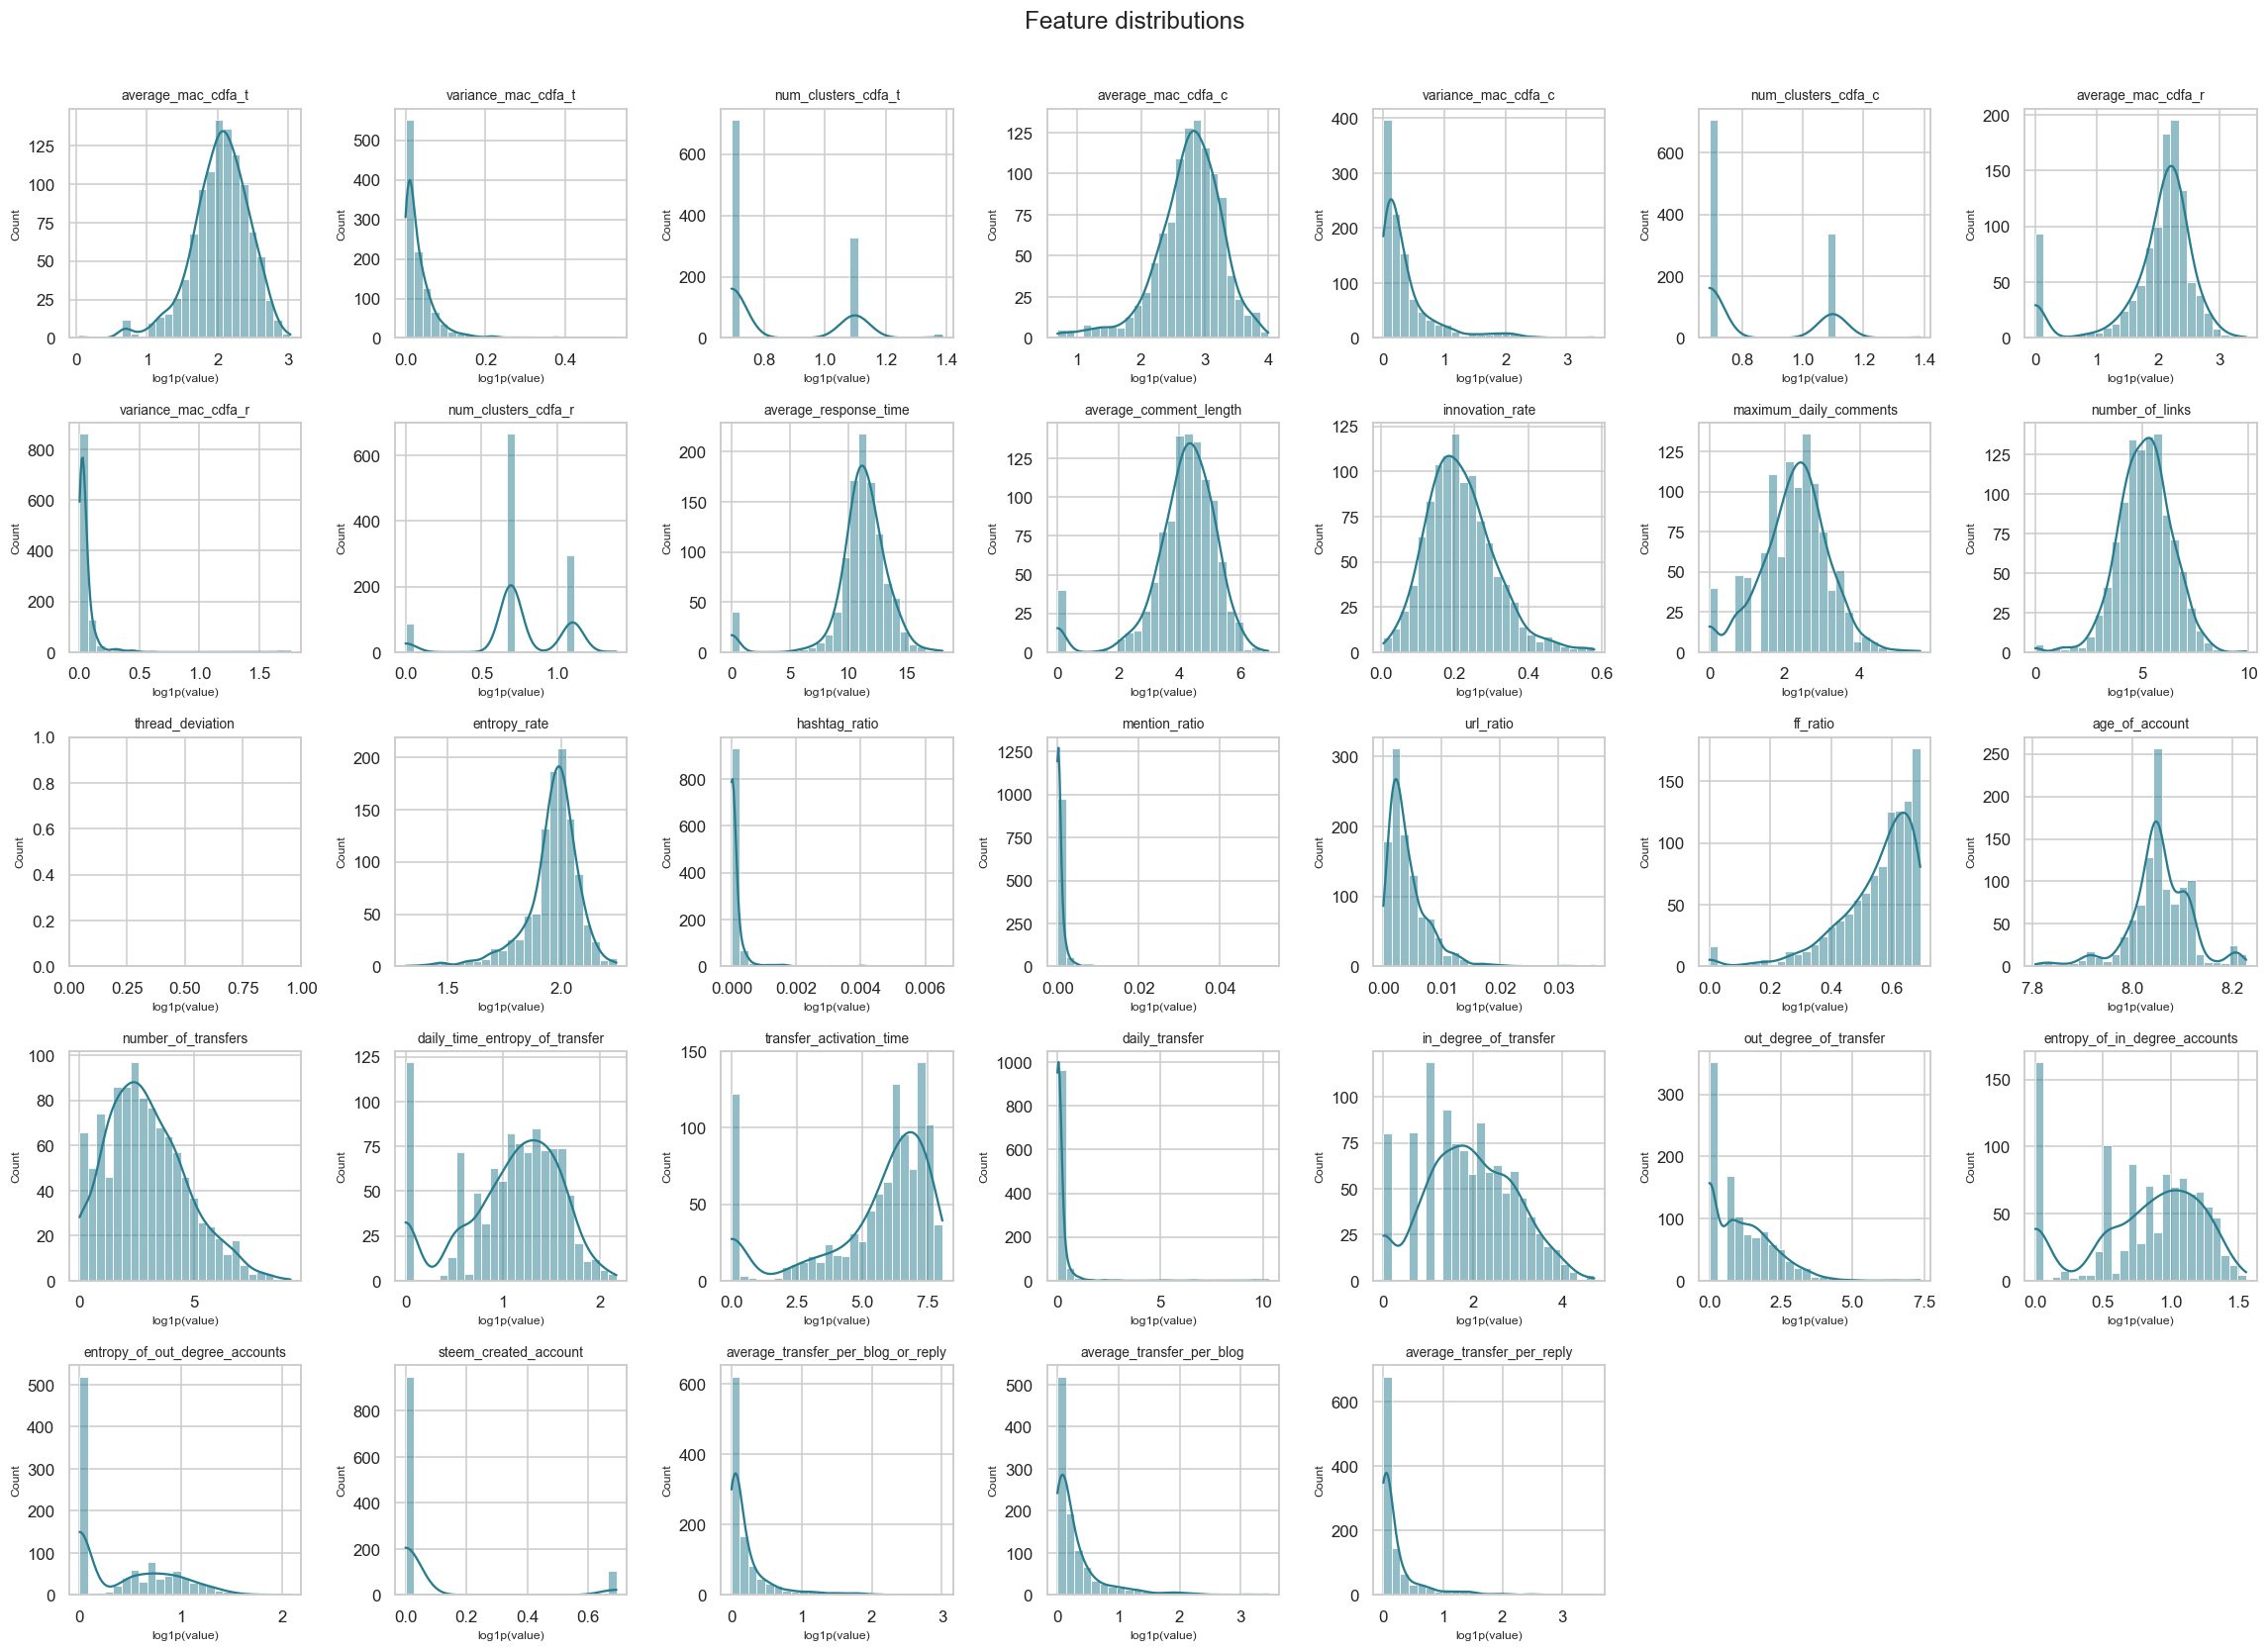

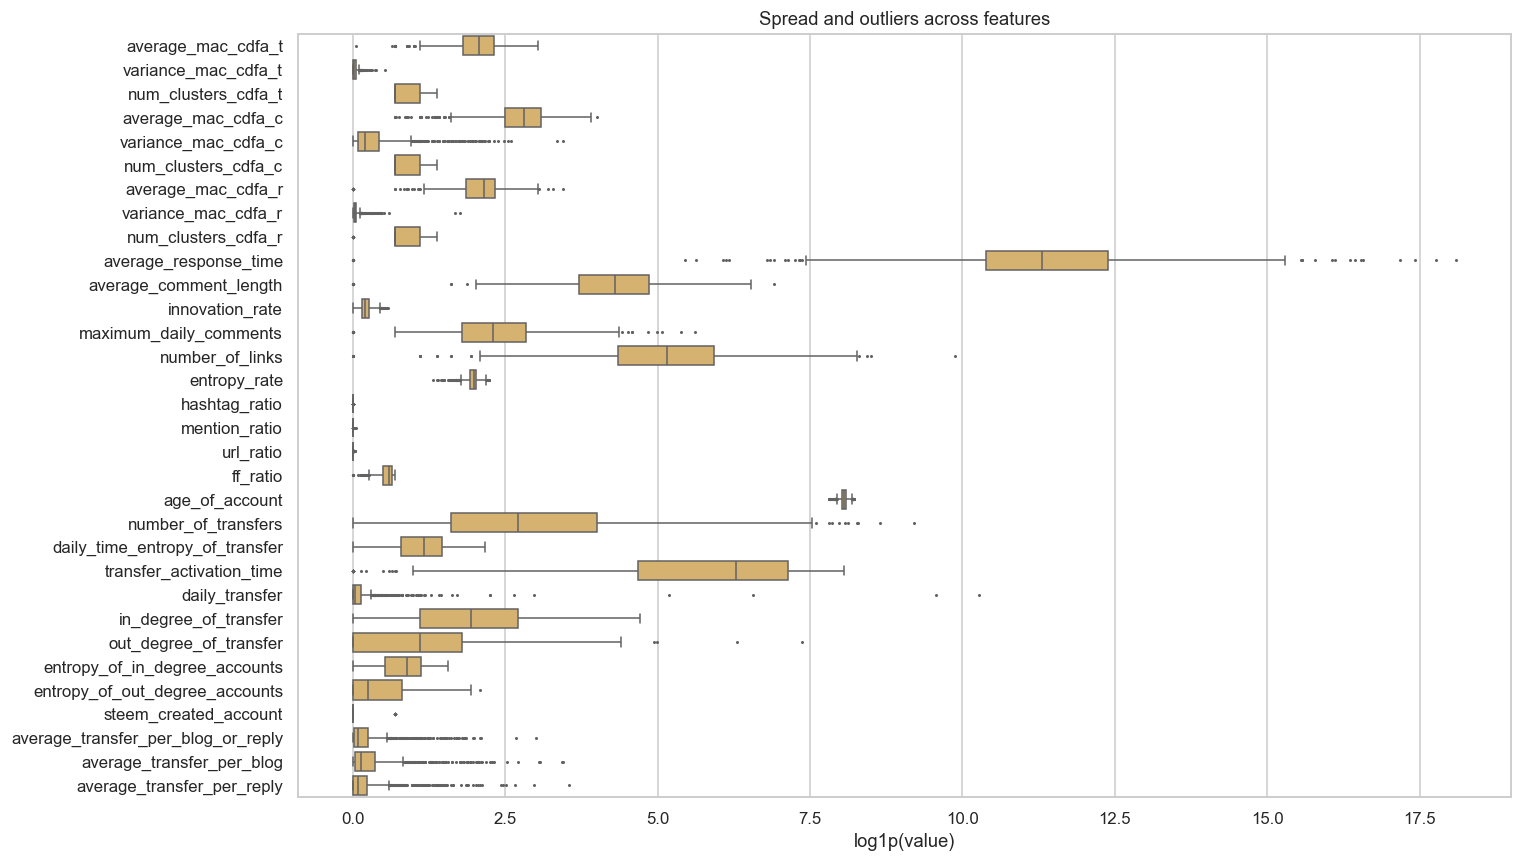

In [9]:
plot_df = np.log1p(df[feature_columns].clip(lower=0))
long_df = plot_df.melt(var_name="Feature", value_name="log1p(value)").dropna()

fig, axes = plt.subplots(5, 7, figsize=(21, 15))
for ax, feature in zip(axes.flat, feature_columns):
    sns.histplot(plot_df[feature].dropna(), bins=25, kde=True, color="#287c8e", ax=ax)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("log1p(value)", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
for ax in axes.flat[len(feature_columns):]:
    ax.set_visible(False)
fig.suptitle("Feature distributions", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 8))
sns.boxplot(data=long_df, x="log1p(value)", y="Feature", color="#e7b75f", fliersize=1, ax=ax)
ax.set_title("Spread and outliers across features")
ax.set_xlabel("log1p(value)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Labels and label-wise spread

Unlabeled accounts are retained in the overview but excluded from the class comparison. The charts below make class imbalance explicit and compare the most variable features across available labels.

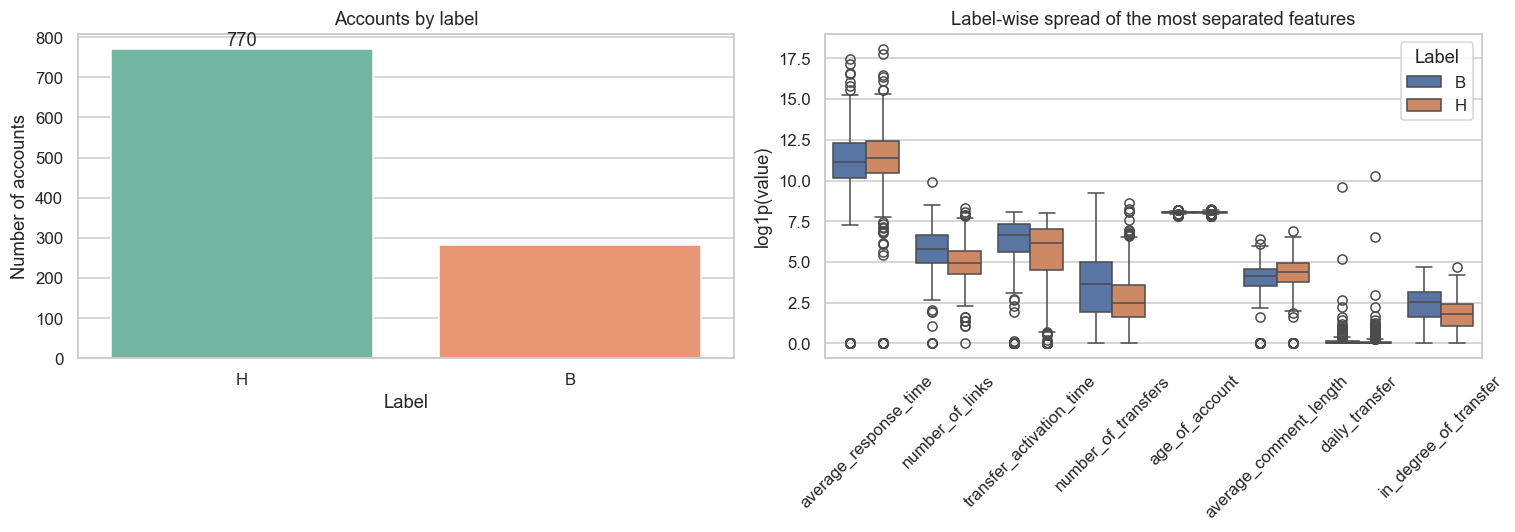

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
label_counts = df["label"].value_counts()
sns.barplot(x=label_counts.index, y=label_counts.values, palette="Set2", ax=axes[0], hue=label_counts.index, legend=False)
axes[0].set(title="Accounts by label", xlabel="Label", ylabel="Number of accounts")
axes[0].bar_label(axes[0].containers[0], fmt="%d")

labeled_df = df[df["label"] != "Unlabeled"].copy()
if labeled_df.empty:
    axes[1].text(0.5, 0.5, "No labeled rows available", ha="center", va="center")
    axes[1].set_axis_off()
else:
    class_means = labeled_df.groupby("label")[feature_columns].mean()
    top_features = class_means.std().sort_values(ascending=False).head(8).index.tolist()
    comparison = labeled_df[["label"] + top_features].melt(id_vars="label", var_name="Feature", value_name="Value")
    comparison["Value"] = np.log1p(comparison["Value"].clip(lower=0))
    sns.boxplot(data=comparison, x="Feature", y="Value", hue="label", ax=axes[1])
    axes[1].set(title="Label-wise spread of the most separated features", xlabel="", ylabel="log1p(value)")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend(title="Label")
plt.tight_layout()
plt.show()

## Labeled accounts only

The following visualizations use only rows with labels `B` or `H`; unlabeled accounts are excluded from every chart in this section.

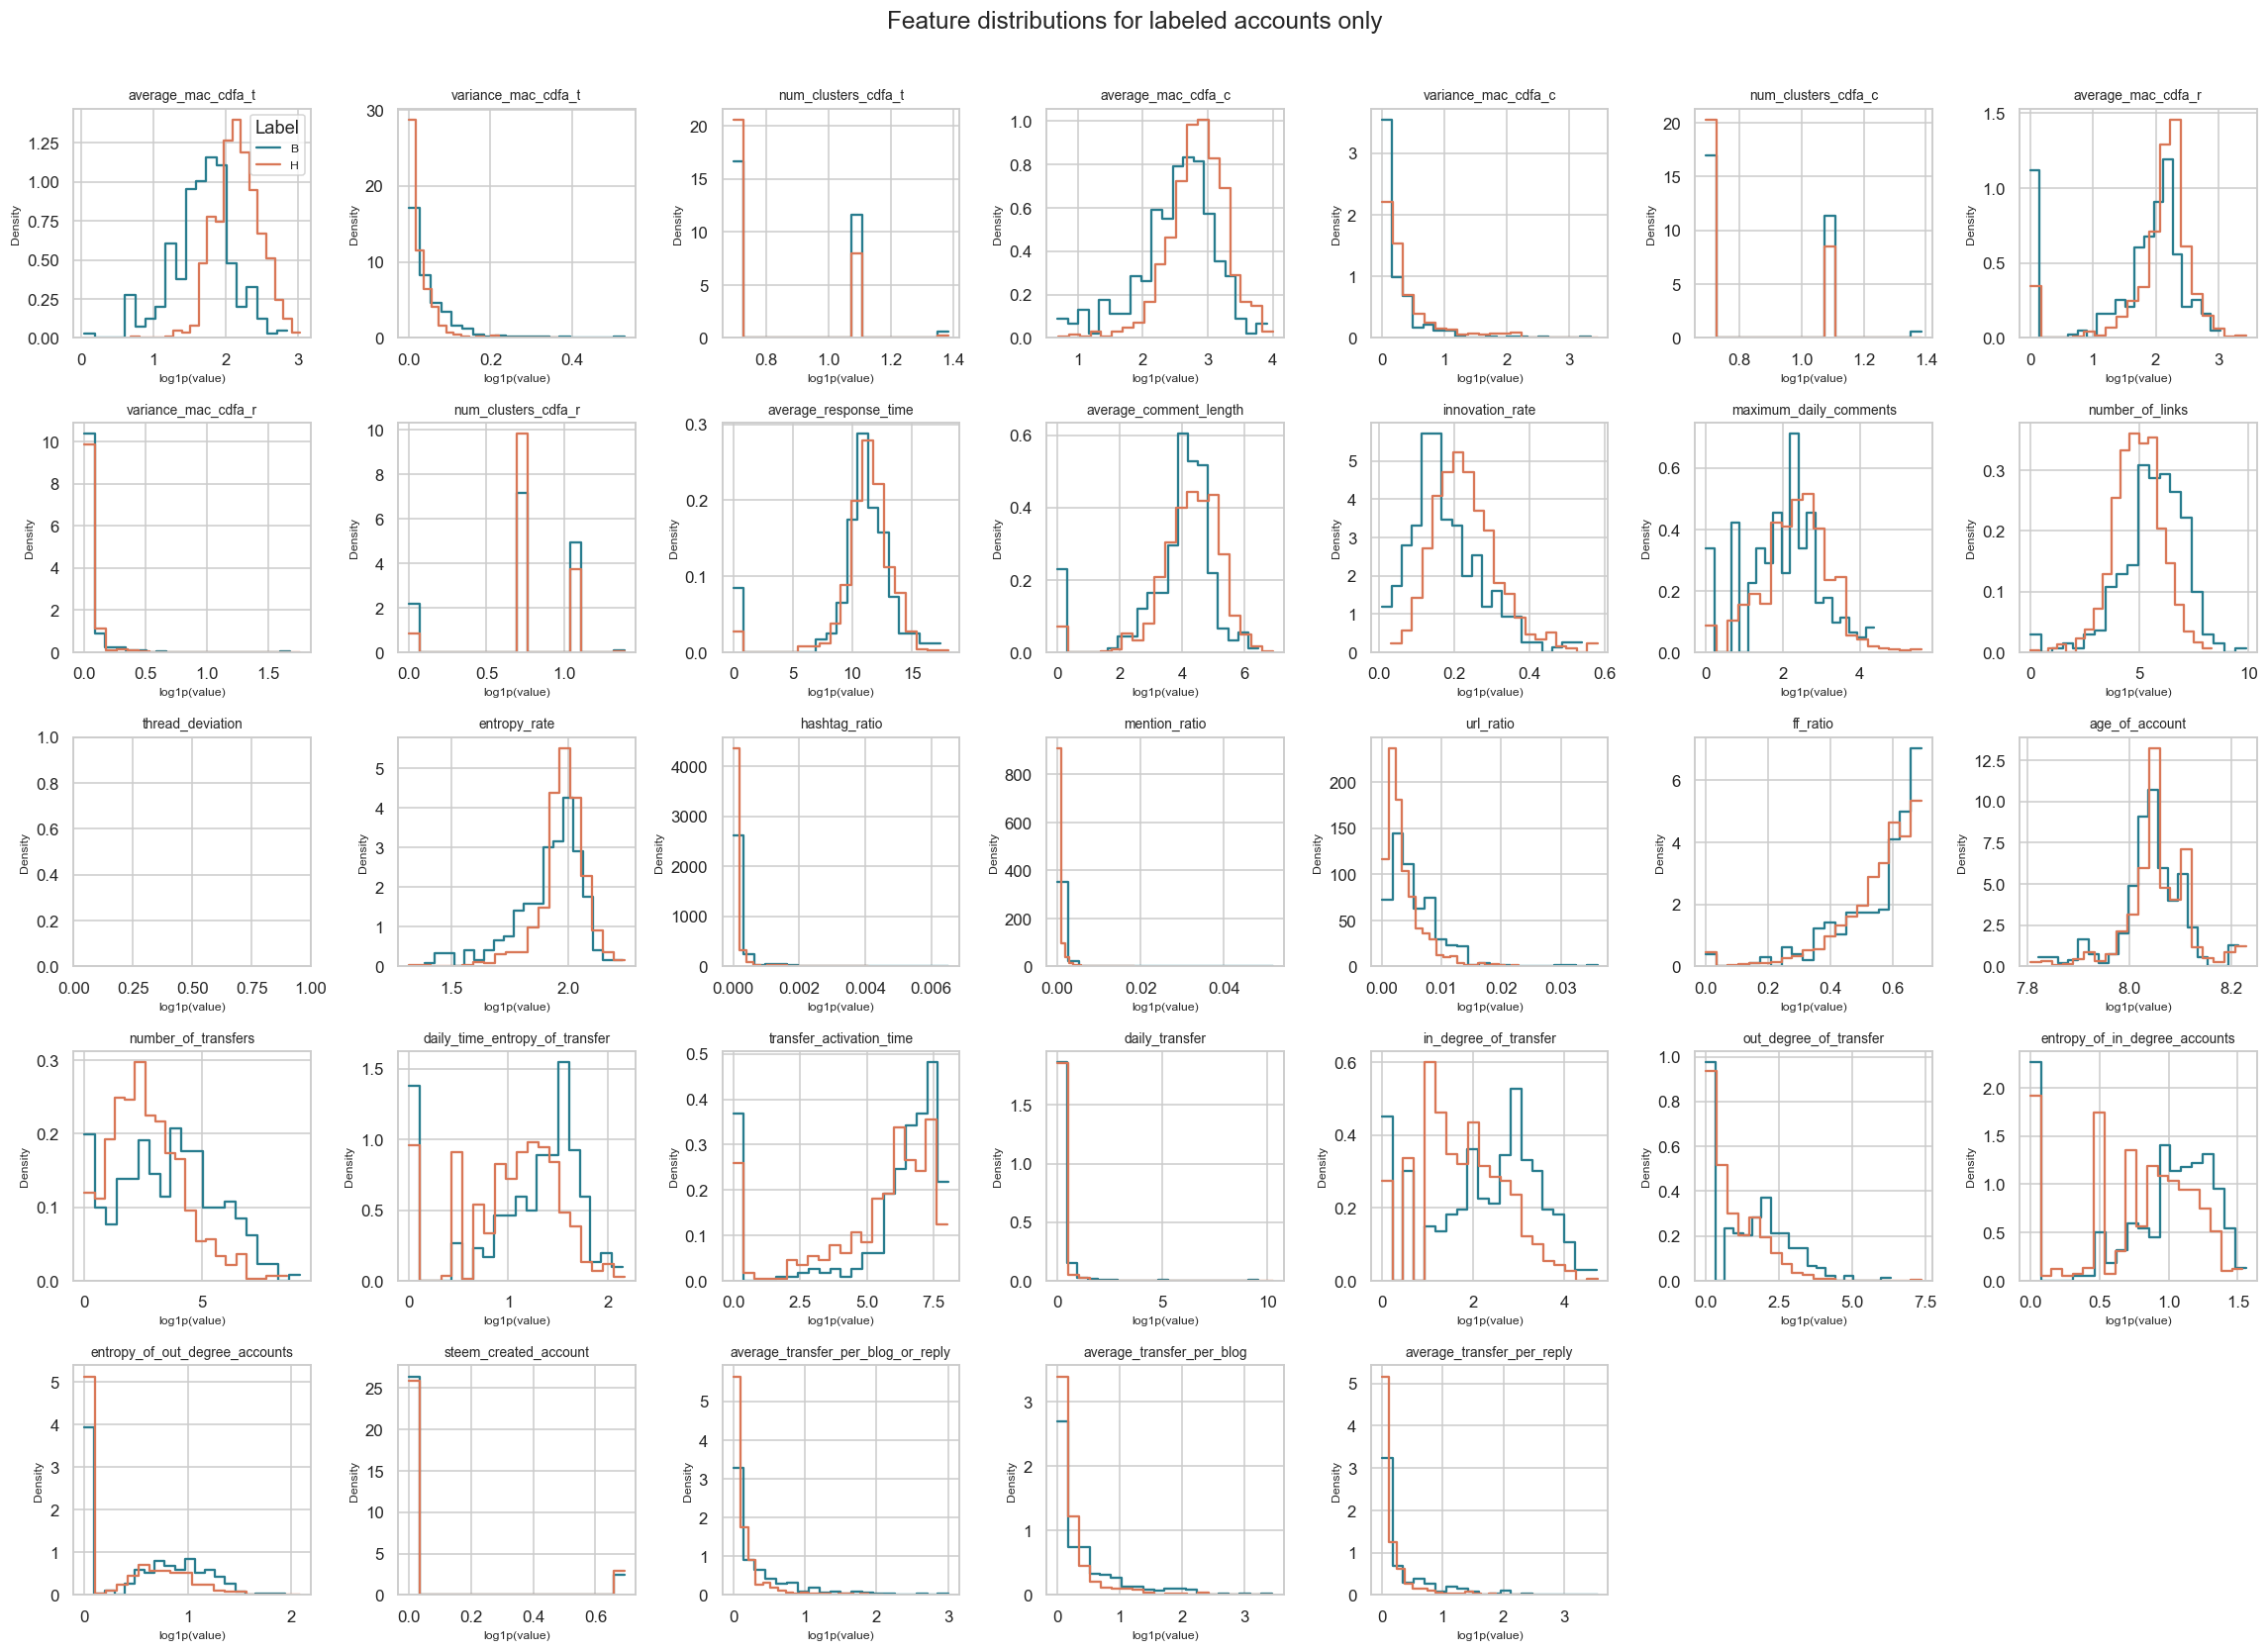

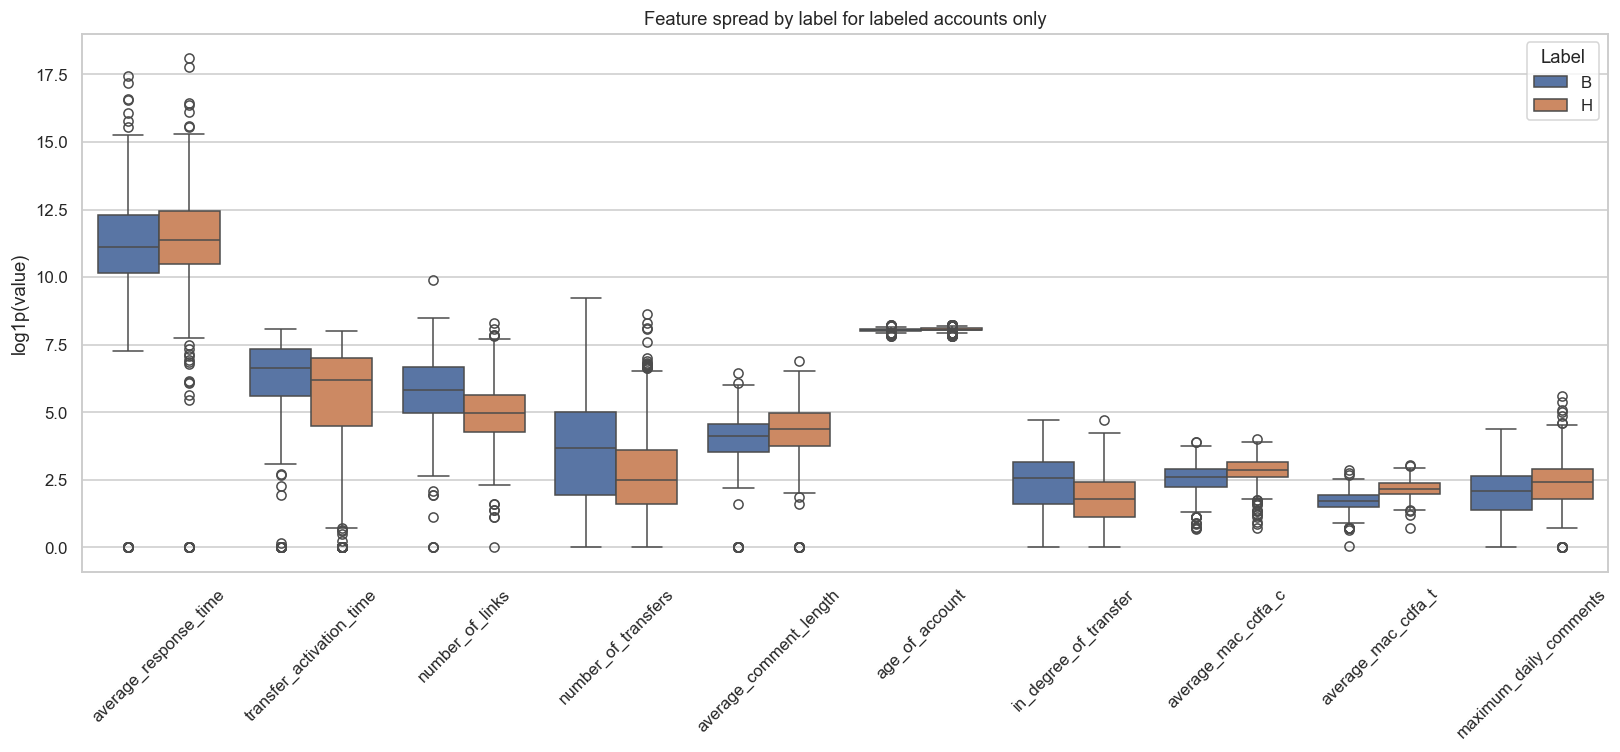

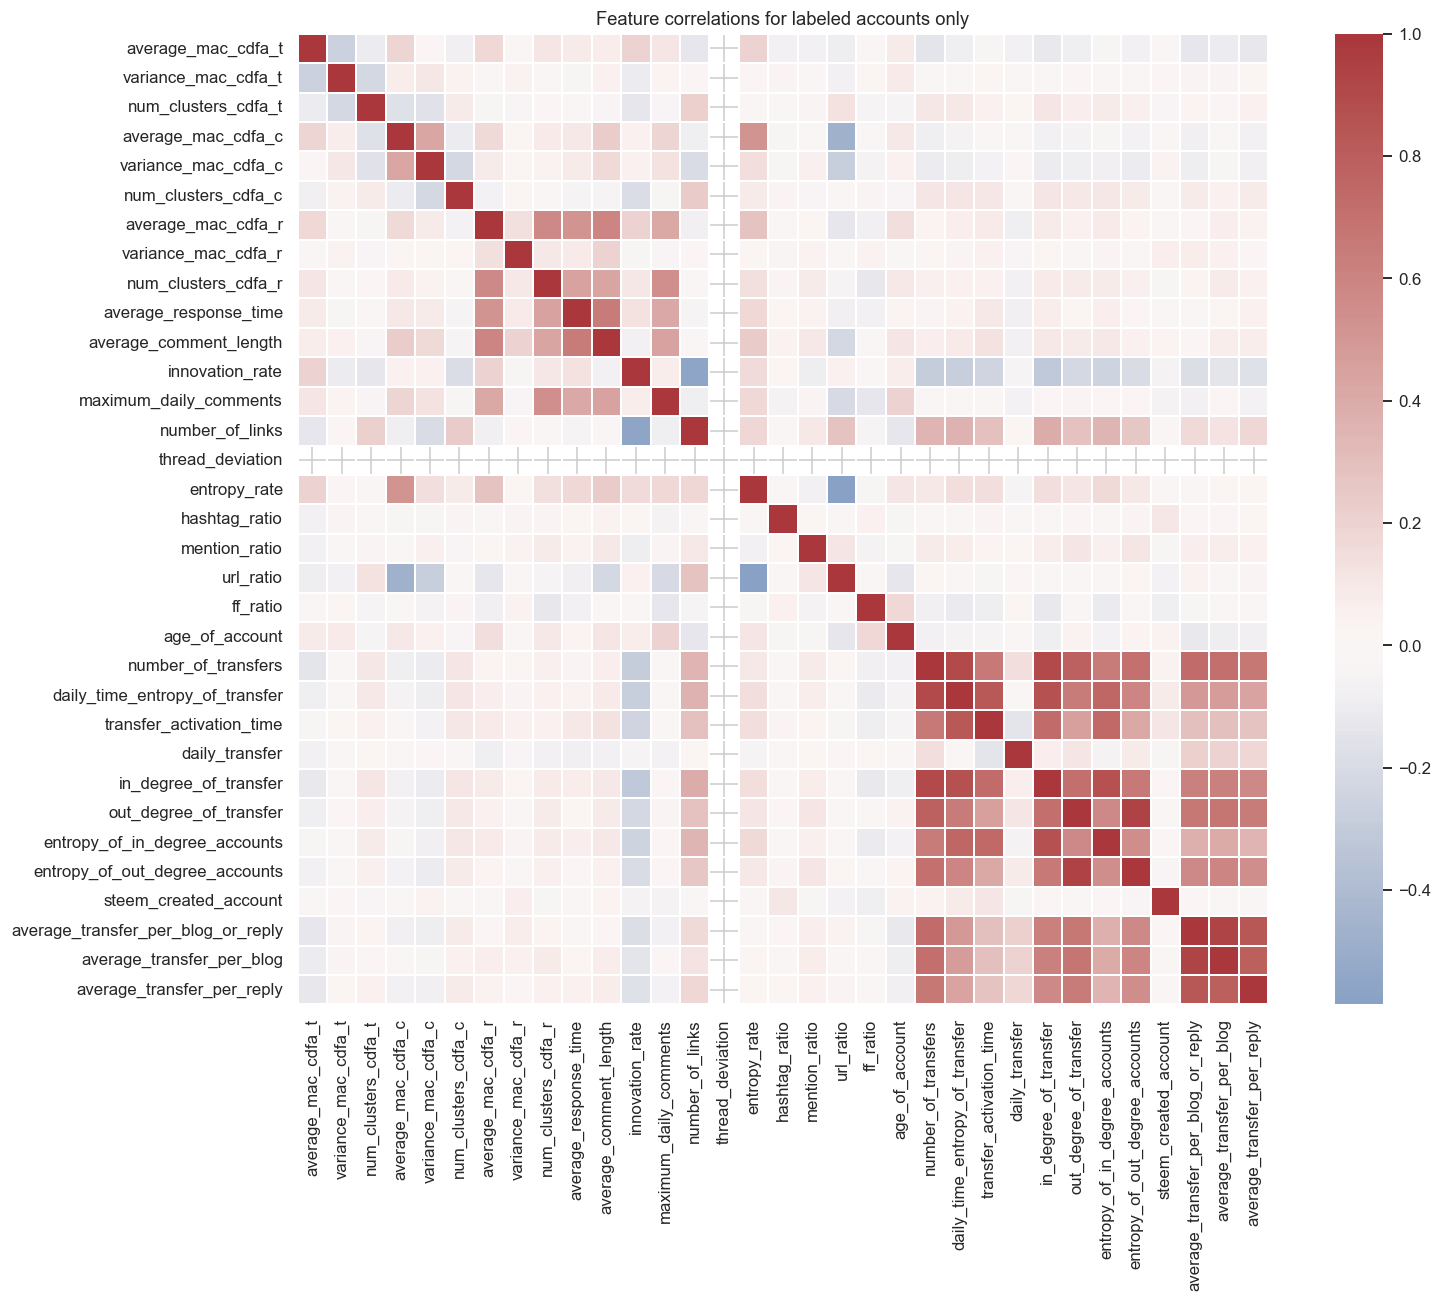

In [11]:
labeled_only = df[df["label"] != "Unlabeled"].copy()

if labeled_only.empty:
    print("No labeled accounts are available.")
else:
    labeled_plot = np.log1p(labeled_only[feature_columns].clip(lower=0))
    labeled_long = labeled_plot.melt(var_name="Feature", value_name="log1p(value)").dropna()

    fig, axes = plt.subplots(5, 7, figsize=(21, 15))
    for ax, feature in zip(axes.flat, feature_columns):
        for label, color in zip(sorted(labeled_only["label"].unique()), ["#287c8e", "#d97757"]):
            values = labeled_plot.loc[labeled_only["label"] == label, feature].dropna()
            sns.histplot(values, bins=20, stat="density", element="step", fill=False,
                         color=color, label=label, ax=ax)
        ax.set_title(feature, fontsize=9)
        ax.set_xlabel("log1p(value)", fontsize=8)
        ax.set_ylabel("Density", fontsize=8)
    for ax in axes.flat[len(feature_columns):]:
        ax.set_visible(False)
    axes.flat[0].legend(title="Label", fontsize=8)
    fig.suptitle("Feature distributions for labeled accounts only", fontsize=16, y=1.01)
    plt.tight_layout()
    plt.show()

    class_medians = labeled_only.groupby("label")[feature_columns].median()
    labeled_top_features = class_medians.std().sort_values(ascending=False).head(10).index.tolist()
    labeled_comparison = labeled_only[["label"] + labeled_top_features].melt(
        id_vars="label", var_name="Feature", value_name="Value"
    )
    labeled_comparison["Value"] = np.log1p(labeled_comparison["Value"].clip(lower=0))

    fig, ax = plt.subplots(figsize=(15, 7))
    sns.boxplot(data=labeled_comparison, x="Feature", y="Value", hue="label", ax=ax)
    ax.set_title("Feature spread by label for labeled accounts only")
    ax.set_xlabel("")
    ax.set_ylabel("log1p(value)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Label")
    plt.tight_layout()
    plt.show()

    labeled_correlation = labeled_plot.corr()
    fig, ax = plt.subplots(figsize=(15, 12))
    sns.heatmap(labeled_correlation, cmap="vlag", center=0, square=True,
                linewidths=0.1, ax=ax)
    ax.set_title("Feature correlations for labeled accounts only")
    plt.tight_layout()
    plt.show()

## Relationships between features

The correlation heatmap shows groups of features that move together. PCA then summarizes the standardized feature space in two dimensions; each point is an account, colored by label when a label is available.

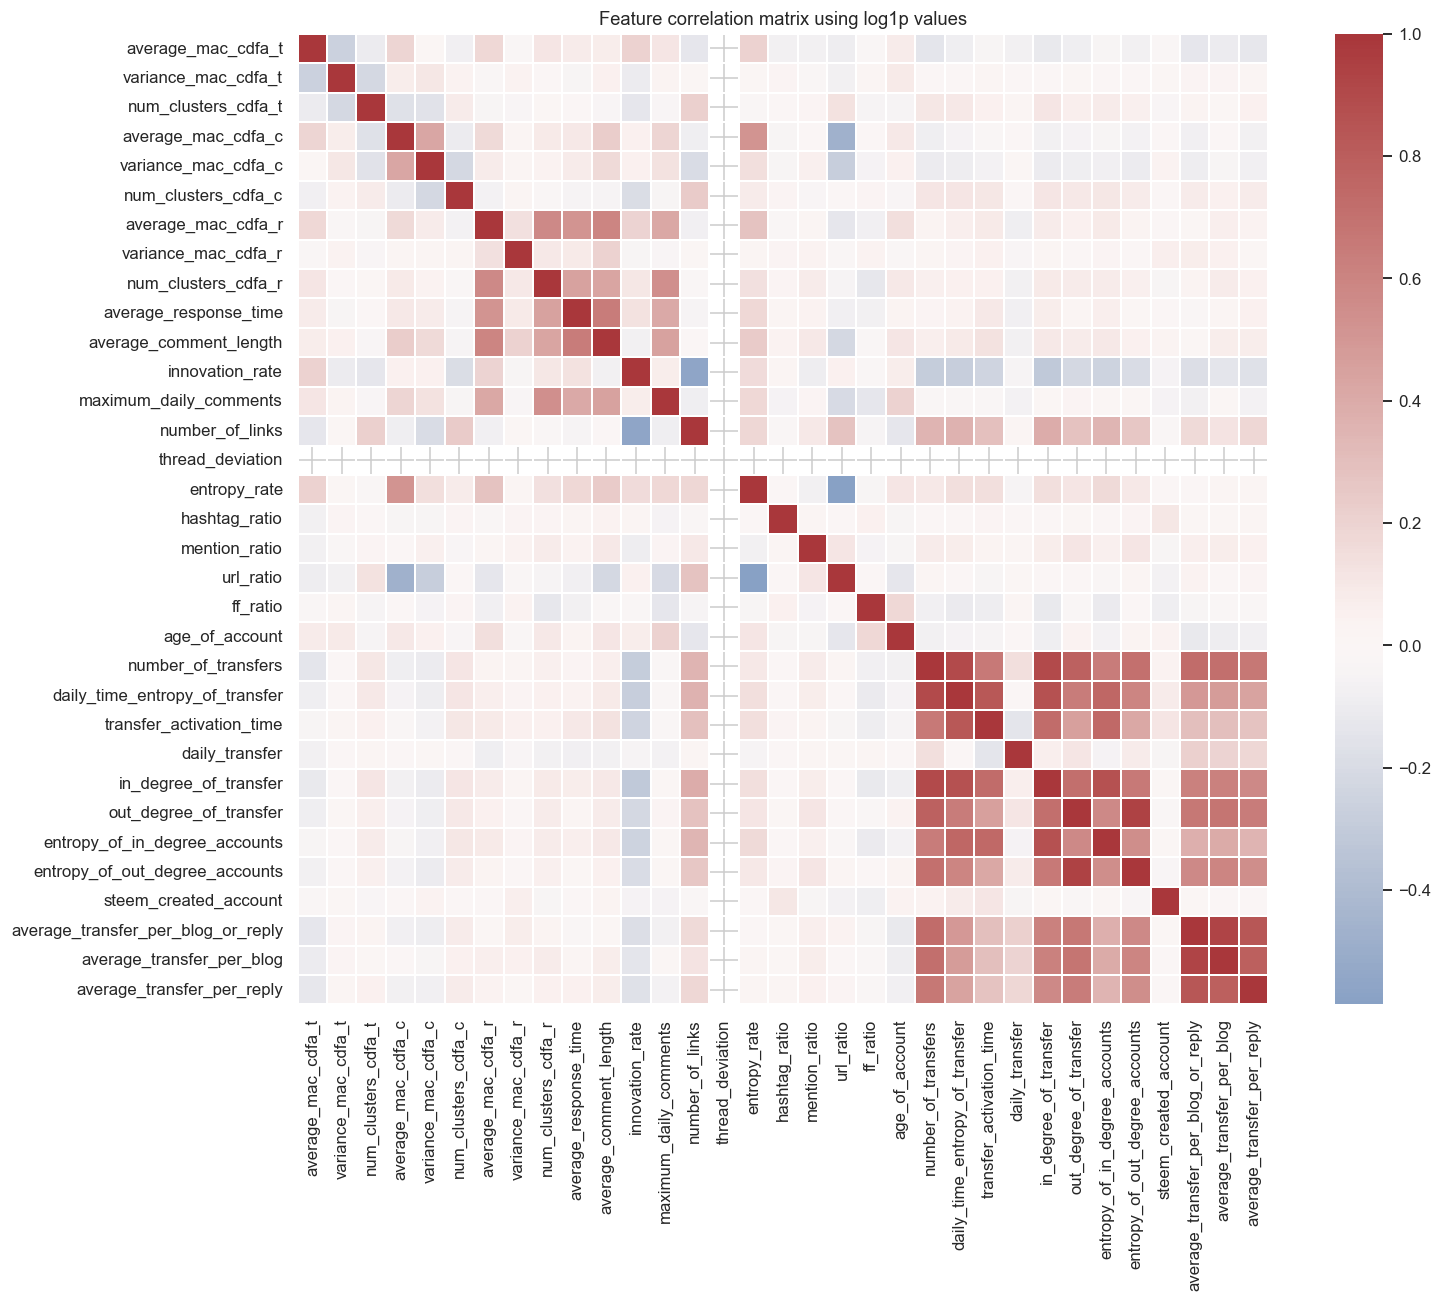

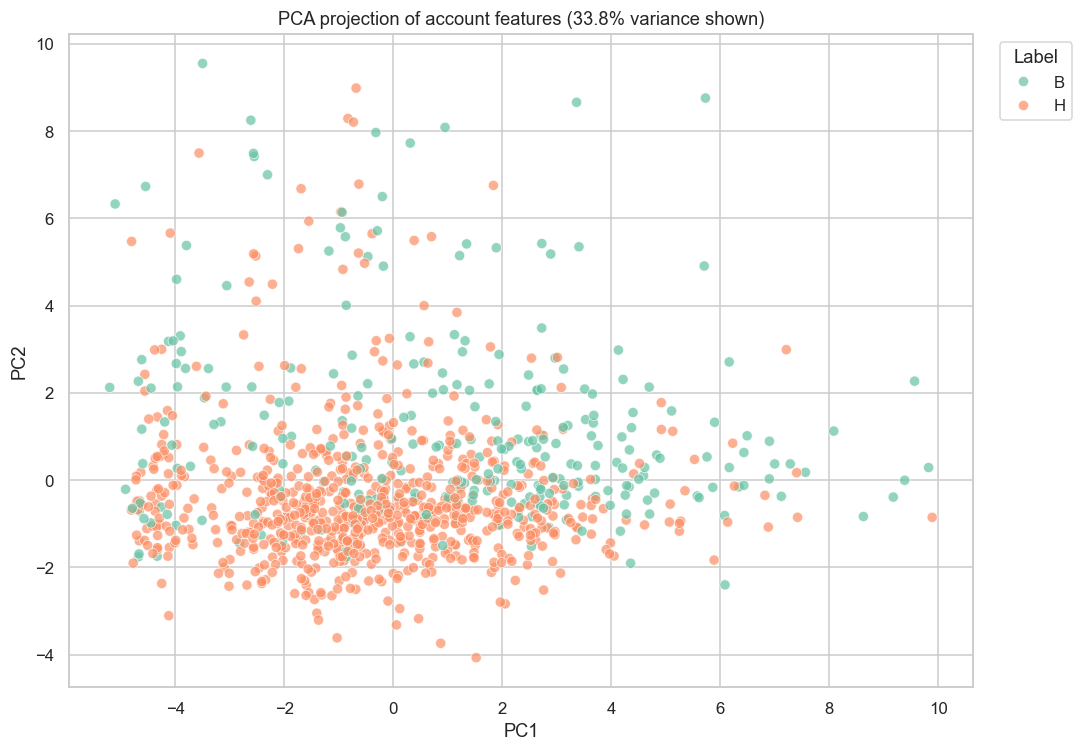

In [12]:
correlation = plot_df.corr()
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(correlation, cmap="vlag", center=0, square=True, linewidths=0.1, ax=ax)
ax.set_title("Feature correlation matrix using log1p values")
plt.tight_layout()
plt.show()

imputed = plot_df.fillna(plot_df.median()).replace([np.inf, -np.inf], 0).fillna(0).to_numpy()
column_means = imputed.mean(axis=0)
column_stds = imputed.std(axis=0)
column_stds[column_stds == 0] = 1
scaled = (imputed - column_means) / column_stds
_, singular_values, right_singular_vectors = np.linalg.svd(scaled, full_matrices=False)
components = scaled @ right_singular_vectors[:2].T
explained_variance_ratio = (singular_values[:2] ** 2) / (singular_values ** 2).sum()
pca_df = pd.DataFrame(components, columns=["PC1", "PC2"])
pca_df["label"] = df["label"].values

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="label", palette="Set2", alpha=0.7, s=45, ax=ax)
ax.set_title(f"PCA projection of account features ({explained_variance_ratio.sum():.1%} variance shown)")
ax.legend(title="Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()